In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from qubit_zz_coupling.utils import load_from_file
from qubit_zz_coupling.models import (two_amp_cos, guess_params_2a,
                                      report_2a)

In [45]:
file_jzz10 = ['results_t1_n0_results_jzz10_test_20251104_193910_gphi.npz',
             'results_t1_n1_results_jzz10_test_20251104_211638_gphi.npz',
             'results_t1_n2_results_jzz10_test_20251104_225359_gphi.npz',
             'results_t1_n3_results_jzz10_test_20251105_003100_gphi.npz',
             'results_t1_n4_results_jzz10_test_20251105_020812_gphi.npz',
             'results_t1_n5_results_jzz10_test_20251105_034543_gphi.npz',
             'results_t1_n6_results_jzz10_test_20251105_052302_gphi.npz',
             'results_t1_n7_results_jzz10_test_20251105_070011_gphi.npz',
             'results_t1_n8_results_jzz10_test_20251105_083738_gphi.npz',
             'results_t1_n9_results_jzz10_test_20251105_101457_gphi.npz']

file_jzz50 = ['results_t1_n0_results_jzz50_re_20251106_233537_gphi.npz',
              'results_t1_n1_results_jzz50_re_20251107_011159_gphi.npz',
              'results_t1_n2_results_jzz50_re_20251107_024810_gphi.npz',
              'results_t1_n3_results_jzz50_re_20251107_042424_gphi.npz',
              'results_t1_n4_results_jzz50_re_20251107_060020_gphi.npz']

file_jzz50_sp =  ['results_t1_n0_results_jzz50_re_nosig_20251107_120648_gphi.npz']

In [ ]:
listfile = "" 
flist = np.load(listfile) 
#flist = file_jzz10 # for example

fldlist = ["expA_list","expB_list","x","y","t_ns"]

expA_list = [] 
expB_list = [] 
x = []  
y = []
t_ns = []

# Load all files
for fname in flist:
    _a, _b, _x, _y, _t = load_from_file(fname, fldlist)
    
    expA_list.append(_a)
    expB_list.append(_b)
    x.append(_x)
    y.append(_y)
    t_ns.append(_t)
    
# Concatenate to a single array for each
expA_list_flat = np.concatenate(expA_list)
expB_list_flat = np.concatenate(expB_list)
x_flat = np.concatenate(x)
y_flat = np.concatenate(y)
t_ns = t_ns[0]

In [ ]:
# make sample
s=1
if s!=1 :
    expA_list_s = [_ea[::s] for _ea in expA_list_flat]
    expB_list_s = [_eb[::s] for _eb in expB_list_flat]
else :
    expA_list_s = expA_list_flat
    expB_list_s = expB_list_flat

146


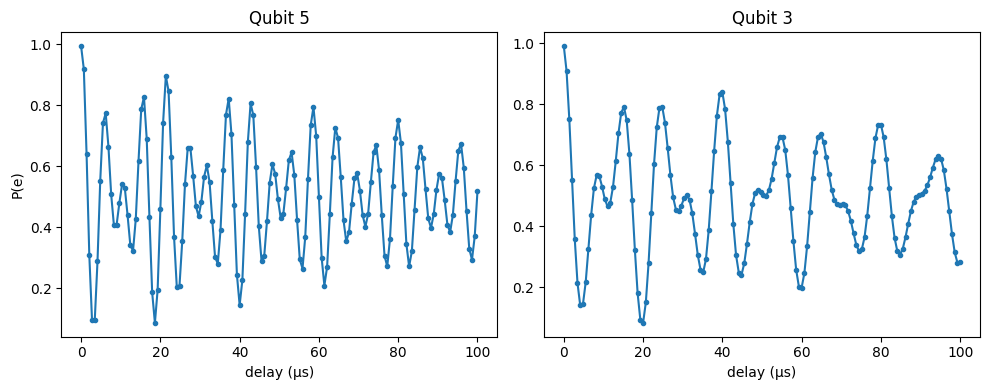

146


In [ ]:
expA = expA_list_s[1]
expB = expB_list_s[1]

t_ns = np.linspace(0, 100000, len(expA)) # resampled times

# ───  Plot ───────────────────────────────────────────────────
plt.figure(figsize=(10,4))
plt.subplot(121); plt.plot(t_ns/1000,expA,'.-'); plt.title('Qubit 5'); plt.xlabel('delay (µs)'); plt.ylabel('P(e)')
plt.subplot(122); plt.plot(t_ns/1000,expB,'.-'); plt.title('Qubit 3'); plt.xlabel('delay (µs)')
plt.tight_layout(); plt.show()
print(len(expA))

In [49]:

expA_t2 = []
expB_t2 = []
expA_p = []
expB_p = [] 

t_s = 1e-9 * t_ns

for expA, expB in zip(expA_list_s, expB_list_s):

      bounds = ([0,0,     0,     0, -np.pi, -np.pi,      0, 0],       # lower
                [1,1,  20e6,  20e6,  np.pi,  np.pi,   4e-4, 1])       # upper A1=0.5
       
      p0A = guess_params_2a(t_ns, expA)
      p0B = guess_params_2a(t_ns, expB)

      #p0A[6] = 50*1e-6 # .01 * p0A[1]
      
      pA,cA,oA,mesgA,_ = curve_fit(two_amp_cos, t_s, expA, p0=p0A, bounds=bounds, maxfev=50000, full_output=True)
      pB,cB,oB,mesgB,_ = curve_fit(two_amp_cos, t_s, expB, p0=p0B, bounds=bounds, maxfev=50000, full_output=True)
      pA,cA,oA,mesgA,_ = curve_fit(two_amp_cos, t_s, expA, p0=pA, bounds=bounds, maxfev=50000, full_output=True)
      pB,cB,oB,mesgB,_ = curve_fit(two_amp_cos, t_s, expB, p0=pB, bounds=bounds, maxfev=50000, full_output=True)
      report_2a("Qubit-A", pA)
      print(mesgA)
      report_2a("Qubit-B", pB)
      print(mesgB)
      expA_t2.append(pA[6])
      expB_t2.append(pB[6])

      expA_p.append(pA)
      expB_p.append(pB)


Qubit-A:  f1 = 0.074 MHz   f2 = 0.149 MHz   A1 = 0.27  A2 = 0.07   T2 = 60.9 µs 0.08611483607020617 -1.4903879499066115
`ftol` termination condition is satisfied.
Qubit-B:  f1 = 0.099 MHz   f2 = 0.126 MHz   A1 = 0.08  A2 = 0.31   T2 = 55.6 µs -1.4966099236176034 -0.0975523159990222
`ftol` termination condition is satisfied.
Qubit-A:  f1 = 0.188 MHz   f2 = 0.138 MHz   A1 = 0.29  A2 = 0.20   T2 = 124.6 µs -0.17545430066052525 -0.13794422881592872
Both `ftol` and `xtol` termination conditions are satisfied.
Qubit-B:  f1 = 0.099 MHz   f2 = 0.126 MHz   A1 = 0.08  A2 = 0.31   T2 = 55.6 µs -1.4972659909914605 -0.09755770561202329
`ftol` termination condition is satisfied.
Qubit-A:  f1 = 0.239 MHz   f2 = 0.189 MHz   A1 = 0.29  A2 = 0.20   T2 = 124.4 µs -0.172105584955103 -0.1338382638804876
`ftol` termination condition is satisfied.
Qubit-B:  f1 = 0.099 MHz   f2 = 0.126 MHz   A1 = 0.08  A2 = 0.31   T2 = 55.6 µs -1.4967864938973128 -0.09757203599285522
`ftol` termination condition is satisfied.

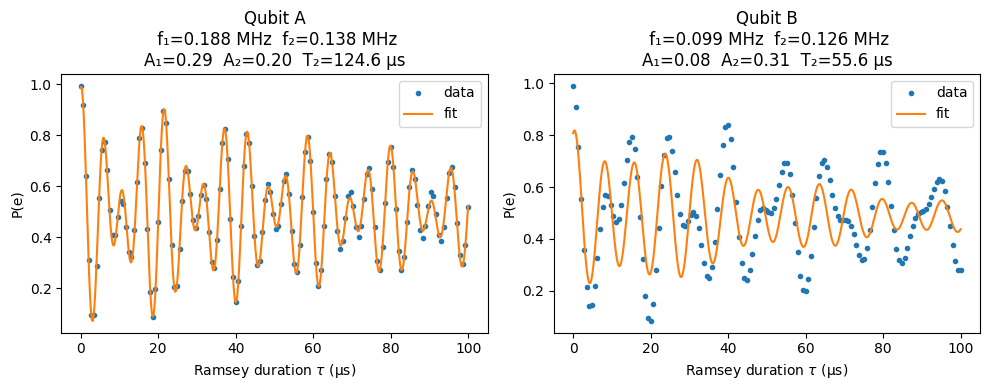

In [50]:
i=1
expA = expA_list_s[i]
expB = expB_list_s[i]
pA = expA_p[i]
pB = expB_p[i]

# --- plots ------------------------------------------------
tf_ns = np.linspace(t_ns[0], t_ns[-1], 1200)
fig, ax = plt.subplots(1,2, figsize=(10,4))

for k,(y_,p,title) in enumerate(zip((expA,expB),(pA,pB),("Qubit A","Qubit B"))):
    ax[k].plot(t_ns*1e-3, y_, '.', label='data')
    (ax[k].plot(tf_ns*1e-3,
                (two_amp_cos)(tf_ns*1e-9, *p),
                label='fit'))
    ax[k].set_title(title +
        (f"\n f₁={p[2]/1e6:.3f} MHz  f₂={p[3]/1e6:.3f} MHz\n"
         f"A₁={p[0]:.2f}  A₂={p[1]:.2f}  T₂={p[6]*1e6:.1f} µs"))
    ax[k].set_xlabel('Ramsey duration $\\tau$ (µs)'); ax[k].set_ylabel('P(e)')
    ax[k].legend()
plt.tight_layout(); plt.show()

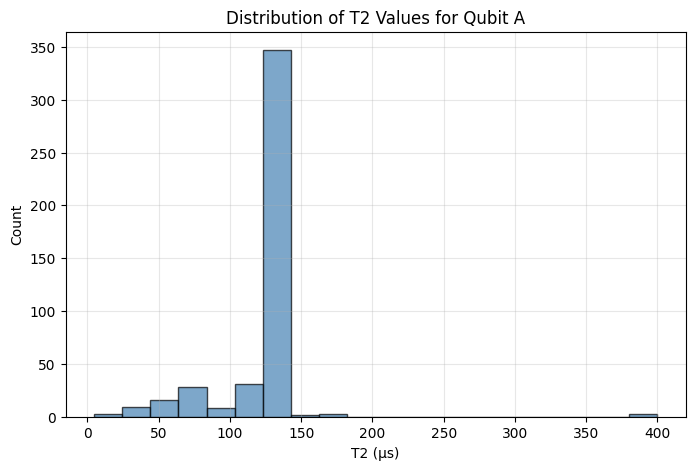

In [43]:
# Create histogram of T2 values
plt.figure(figsize=(8,5))
plt.hist(np.array(expA_t2) * 1e6, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
plt.xlabel('T2 (µs)')
plt.ylabel('Count')
plt.title('Distribution of T2 Values for Qubit A')
plt.grid(True, alpha=0.3)
plt.show()

In [51]:
def find_avg(arr, chunk_size):
    # Reshape x into chunks of 30 elements
    # If x length is not divisible by 30, it will truncate the last incomplete chunk
    n_complete_chunks = len(arr) // chunk_size
    arr_chunks = arr[:n_complete_chunks * chunk_size].reshape(-1, chunk_size)

    # Calculate mean across chunks (axis 0)
    arr_avg = np.mean(arr_chunks, axis=0)
    return arr_avg

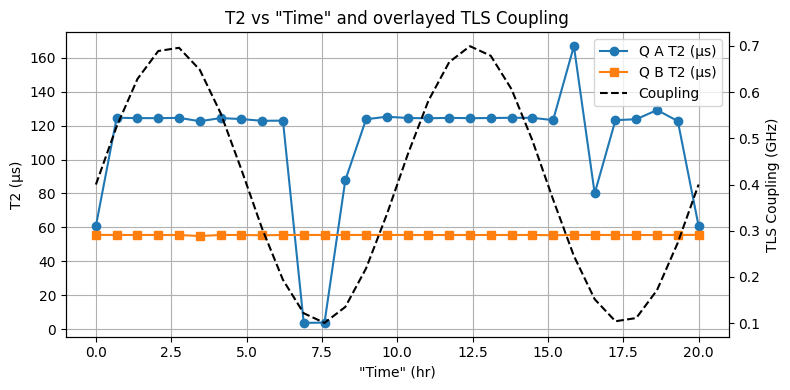

In [52]:
xa = np.array(find_avg(x,30))
expA_t2 = np.array(find_avg(np.array(expA_t2),30))
expB_t2 = np.array(find_avg(np.array(expB_t2),30))

# trim to common length if needed
n = min(len(xa), len(expA_t2), len(expB_t2), len(y))
xa = xa[:n]
expA_t2 = expA_t2[:n]
expB_t2 = expB_t2[:n]
y_plot = np.array(y)[:n]

fig, ax = plt.subplots(figsize=(8,4))

# left axis: T2 in µs
ln1 = ax.plot(xa, expA_t2 * 1e6, 'o-', label='Q A T2 (µs)', color='tab:blue')
ln2 = ax.plot(xa, expB_t2 * 1e6, 's-', label='Q B T2 (µs)', color='tab:orange')
ax.set_xlabel('"Time" (hr)')
ax.set_ylabel('T2 (µs)')
ax.set_title('T2 vs "Time" and overlayed TLS Coupling')
ax.grid(True)

# right axis: y (different scale)
ax2 = ax.twinx()
ln3 = ax2.plot(xa, y_plot, 'k--', label='Coupling', linewidth=1.5)
ax2.set_ylabel('TLS Coupling (GHz)')

# combined legend
lines = ln1 + ln2 + ln3
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc='best')

plt.tight_layout()
plt.show()